In [46]:
# Import necessary libraries

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [47]:
# Load cleaned data

df = pd.read_csv('../data/support_tickets_cleaned.csv')
X_text = df['clean_text']
y = df['priority_class']

In [48]:
# Vectorize text
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english')
X = vectorizer.fit_transform(X_text)
print("TF-IDF shape:", X.shape)

TF-IDF shape: (1820, 2000)


In [49]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance classes
sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(X, y)

print("Before SMOTE:", y.value_counts().to_dict())
print("After SMOTE:", pd.Series(y_resampled).value_counts().to_dict())

Before SMOTE: {'Medium': 1558, 'High': 213, 'Low': 49}
After SMOTE: {'Medium': 1558, 'High': 1558, 'Low': 1558}


In [50]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

In [51]:
sm = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = sm.fit_resample(X_train, y_train)

In [52]:
# Train classifier with class balancing
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train_resampled, y_train_resampled)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [53]:
# Predict and evaluate
y_pred = model.predict(X_test)
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['High', 'Medium', 'Low']))

Classification Report:
              precision    recall  f1-score   support

        High       0.26      0.55      0.35        42
      Medium       0.20      0.20      0.20        10
         Low       0.91      0.77      0.84       312

    accuracy                           0.73       364
   macro avg       0.46      0.51      0.46       364
weighted avg       0.82      0.73      0.76       364



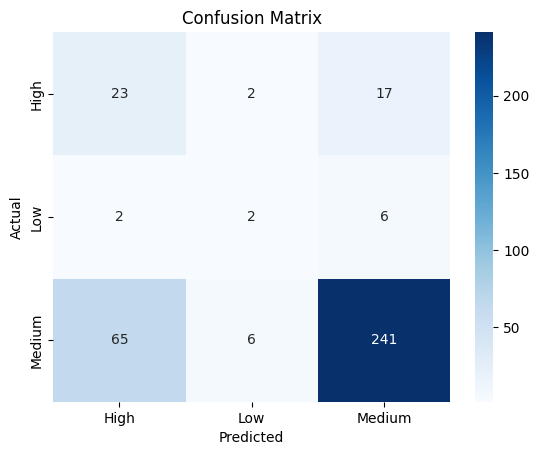

In [54]:
# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred, labels=model.classes_)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [55]:
# Save model and vectorizer
joblib.dump(model, '../models/priority_classifier.pkl')
joblib.dump(vectorizer, '../models/tfidf_vectorizer.pkl')
print("Model and vectorizer saved.")

Model and vectorizer saved.


In [56]:
from collections import Counter
print("y_train distribution:", Counter(y_train))
print("y_test distribution:", Counter(y_test))


y_train distribution: Counter({'Medium': 1246, 'High': 171, 'Low': 39})
y_test distribution: Counter({'Medium': 312, 'High': 42, 'Low': 10})


In [57]:
# Recover the original test data (for display)
df_test = df.iloc[y_test.index].copy()

# Add predictions
df_test['predicted_priority'] = y_pred

# Export to CSV
df_test.to_csv('../data/predicted_support_tickets.csv', index=False)
